In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dikshanamr/cmapss/CMaps/RUL_FD002.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/test_FD003.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/Damage Propagation Modeling.pdf
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/readme.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/train_FD003.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/test_FD004.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/train_FD004.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/x.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/test_FD002.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/train_FD001.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/train_FD002.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/RUL_FD001.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/RUL_FD004.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/RUL_FD003.txt
/kaggle/input/datasets/dikshanamr/cmapss/CMaps/test_FD001.txt


In [5]:
import pandas as pd

# Column names kudukkrom, file la header illa
cols = ['engine_id', 'cycle', 'setting1', 'setting2', 'setting3'] + [f's{i}' for i in range(1, 22)]

path = '/kaggle/input/datasets/dikshanamr/cmapss/CMaps/train_FD001.txt'
df = pd.read_csv(path, sep=r'\s+', header=None, names=cols)

print(df.shape)   # evlo rows, evlo columns
df.head()         # first 5 rows

(20631, 26)


,engine_id,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


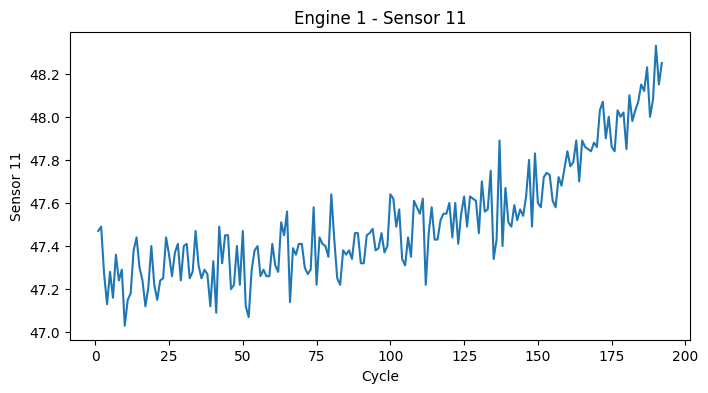

In [6]:
import matplotlib.pyplot as plt

e1 = df[df['engine_id'] == 1]    # engine 1 data mattum edukkrom

plt.figure(figsize=(8, 4))
plt.plot(e1['cycle'], e1['s11'])
plt.xlabel('Cycle')
plt.ylabel('Sensor 11')
plt.title('Engine 1 - Sensor 11')
plt.show()

In [7]:
# Ovvoru engine oda last cycle (fail aana cycle)
max_cycle = df.groupby('engine_id')['cycle'].max()

df['max_cycle'] = df['engine_id'].map(max_cycle)
df['RUL'] = df['max_cycle'] - df['cycle']

df[['engine_id', 'cycle', 'max_cycle', 'RUL']].head(10)

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [8]:
# Maaradha (constant) sensors kandupidikkalam
sensor_cols = [f's{i}' for i in range(1, 22)]
print(df[sensor_cols].std().round(3))

s1      0.000
s2      0.500
s3      6.131
s4      9.001
s5      0.000
s6      0.001
s7      0.885
s8      0.071
s9     22.083
s10     0.000
s11     0.267
s12     0.738
s13     0.072
s14    19.076
s15     0.038
s16     0.000
s17     1.549
s18     0.000
s19     0.000
s20     0.181
s21     0.108
dtype: float64


In [9]:
# Sensors that are constant (std near 0) carry no information, so drop them
drop_sensors = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']

# Keep only the useful sensors
features = [c for c in sensor_cols if c not in drop_sensors]

print(features)
print(len(features), "sensors selected")

['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
14 sensors selected


In [10]:
# Early in an engine's life, degradation is not visible yet,
# so we cap RUL at 125 (a standard practice for C-MAPSS)
CAP = 125

df['RUL_capped'] = df['RUL'].clip(upper=CAP)

print(df[['engine_id', 'cycle', 'RUL', 'RUL_capped']].head(3))
print(df[['engine_id', 'cycle', 'RUL', 'RUL_capped']].tail(3))

   engine_id  cycle  RUL  RUL_capped
0          1      1  191         125
1          1      2  190         125
2          1      3  189         125
       engine_id  cycle  RUL  RUL_capped
20628        100    198    2           2
20629        100    199    1           1
20630        100    200    0           0


In [11]:
# Sensor readings are noisy, so smooth them with a rolling mean (window = 10 cycles)
WINDOW = 10

for col in features:
    df[col + '_roll'] = (
        df.groupby('engine_id')[col]
        .transform(lambda x: x.rolling(WINDOW, min_periods=1).mean())
    )

roll_features = [c + '_roll' for c in features]
print(len(roll_features), "rolling features created")

14 rolling features created


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Split by engine again (same random_state so the split is identical)
engine_ids = df['engine_id'].unique()
train_ids, val_ids = train_test_split(engine_ids, test_size=0.2, random_state=42)

train = df[df['engine_id'].isin(train_ids)]
val = df[df['engine_id'].isin(val_ids)]

X_train, y_train = train[roll_features], train['RUL_capped']
X_val, y_val = val[roll_features], val['RUL_capped']

model2 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model2.fit(X_train, y_train)

pred2 = model2.predict(X_val)
rmse2 = np.sqrt(mean_squared_error(y_val, pred2))
print("Improved RMSE:", round(rmse2, 2))

Improved RMSE: 17.68


In [13]:
# Compare both models on the SAME target (capped RUL) for a fair comparison
# Model 1: raw sensors, trained on uncapped RUL, evaluated on capped RUL
X_train1, X_val1 = train[features], val[features]

model1 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model1.fit(X_train1, train['RUL'])

pred1 = np.clip(model1.predict(X_val1), None, CAP)   # cap predictions too
rmse1 = np.sqrt(mean_squared_error(val['RUL_capped'], pred1))

print("Baseline RMSE (raw sensors, uncapped training):", round(rmse1, 2))
print("Improved RMSE (rolling + capped training):    ", round(rmse2, 2))

Baseline RMSE (raw sensors, uncapped training): 19.09
Improved RMSE (rolling + capped training):     17.68


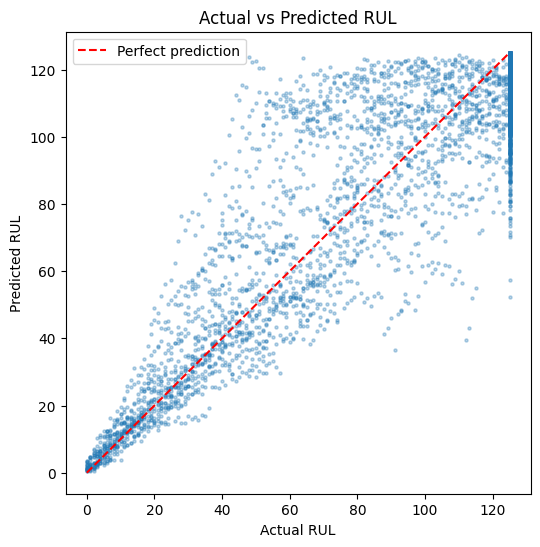

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(val['RUL_capped'], pred2, alpha=0.3, s=5)
plt.plot([0, CAP], [0, CAP], 'r--', label='Perfect prediction')
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL')
plt.legend()
plt.show()

In [15]:
from xgboost import XGBRegressor

# Train XGBoost on the same features and capped target
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_val)
rmse_xgb = np.sqrt(mean_squared_error(y_val, pred_xgb))
print("XGBoost RMSE:", round(rmse_xgb, 2))

XGBoost RMSE: 17.39


In [16]:
!pip install shap -q

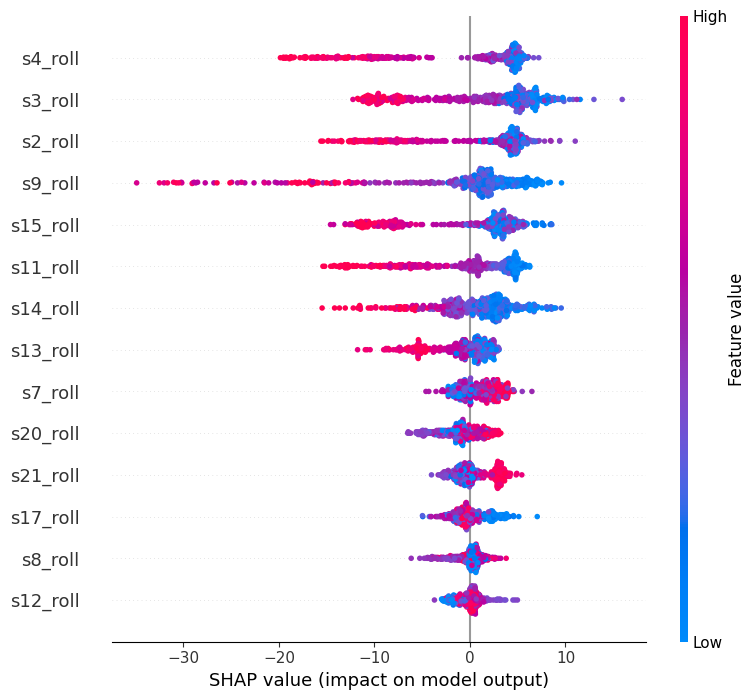

In [17]:
import shap
import matplotlib.pyplot as plt

# Use a sample of validation data to keep it fast
X_sample = X_val.sample(500, random_state=42)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_sample)

# Summary plot: which sensors matter most
shap.summary_plot(shap_values, X_sample)

In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Define "failure soon" as RUL <= 30 cycles
THRESHOLD = 30

actual_alert = (val['RUL'] <= THRESHOLD).astype(int)
pred_alert = (pred_xgb <= THRESHOLD).astype(int)

print("Precision:", round(precision_score(actual_alert, pred_alert), 3))
print("Recall:   ", round(recall_score(actual_alert, pred_alert), 3))
print("F1:       ", round(f1_score(actual_alert, pred_alert), 3))

Precision: 0.913
Recall:    0.829
F1:        0.869


In [19]:
# Keep the real failure definition at RUL <= 30,
# but raise the alert trigger to see the precision/recall trade-off
actual_alert = (val['RUL'] <= 30).astype(int)

for trigger in [30, 35, 40, 45, 50]:
    pred_alert = (pred_xgb <= trigger).astype(int)
    p = precision_score(actual_alert, pred_alert)
    r = recall_score(actual_alert, pred_alert)
    print(f"Alert when predicted RUL <= {trigger}:  Precision={p:.3f}  Recall={r:.3f}")

Alert when predicted RUL <= 30:  Precision=0.913  Recall=0.829
Alert when predicted RUL <= 35:  Precision=0.829  Recall=0.894
Alert when predicted RUL <= 40:  Precision=0.746  Recall=0.932
Alert when predicted RUL <= 45:  Precision=0.669  Recall=0.953
Alert when predicted RUL <= 50:  Precision=0.617  Recall=0.973


In [20]:
import joblib

# Save the trained model and feature list for the dashboard
joblib.dump(xgb, '/kaggle/working/xgb_model.pkl')
joblib.dump(roll_features, '/kaggle/working/roll_features.pkl')

print("Saved!")

Saved!


In [21]:
# Save data (with rolling features) for the dashboard demo
demo = df[['engine_id', 'cycle', 'RUL'] + roll_features]
demo.to_csv('/kaggle/working/demo_data.csv', index=False)

print("Demo data saved:", demo.shape)

Demo data saved: (20631, 17)


In [22]:
import xgboost

# Save in XGBoost's own portable format (safer across versions)
xgb.save_model('/kaggle/working/xgb_model.json')
print("xgboost version:", xgboost.__version__)

xgboost version: 3.4.1
